# Lab 03 — Bayes' and k-NN Classifiers for Forest vs Urban

We classify satellite RGB pixels as **forest** or **urban** using two classifiers built from scratch:

1. **Bayes classifier** with parametric Gaussian PDFs fitted on pure training patches
2. **k-NN classifier** for $k \in \{1,3,5\}$

| File | Role |
|---|---|
| `forest.png` | Pure forest training pixels |
| `urban.png` | Pure urban training pixels |
| `mixed.png` | Mixed test scene to classify |

**Colour key:** Urban = red, Forest = blue.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.spatial.distance import cdist

%matplotlib inline
np.random.seed(0)

In [2]:
def load_rgb(path):
    """Load image as uint8 RGB array."""
    return np.array(Image.open(path).convert('RGB'))


def pixels(img):
    """Flatten HxWx3 image to Nx3 float array."""
    return img.reshape(-1, 3).astype(float)


def colourise(labels, shape):
    """Map labels to RGB: 1 = urban (red), 0 = forest (blue)."""
    out = np.zeros((*shape[:2], 3), dtype=np.uint8)
    out[labels == 1] = (220, 40, 40)
    out[labels == 0] = (40, 80, 220)
    return out


def overlay(rgb, labels, alpha=0.45):
    """Blend original image with class colours."""
    mask = colourise(labels, rgb.shape).astype(float)
    base = rgb.astype(float)
    return np.clip((1 - alpha) * base + alpha * mask, 0, 255).astype(np.uint8)


def class_share(labels):
    urban = 100.0 * np.mean(labels == 1)
    return urban, 100.0 - urban

## 0. Load data and inspect training histograms

forest: (200, 200, 3) | urban: (200, 200, 3) | mixed: (200, 200, 3)
Training pixels — forest: 40000 | urban: 40000


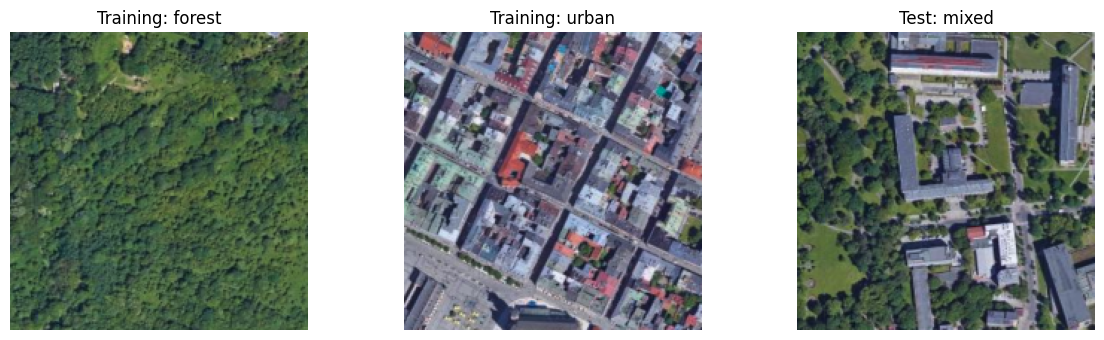

In [3]:
forest_img = load_rgb('forest.png')
urban_img = load_rgb('urban.png')
mixed_img = load_rgb('mixed.png')

X_forest = pixels(forest_img)
X_urban = pixels(urban_img)
X_test = pixels(mixed_img)

print('forest:', forest_img.shape, '| urban:', urban_img.shape, '| mixed:', mixed_img.shape)
print('Training pixels — forest:', len(X_forest), '| urban:', len(X_urban))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(forest_img); axes[0].set_title('Training: forest'); axes[0].axis('off')
axes[1].imshow(urban_img);  axes[1].set_title('Training: urban');  axes[1].axis('off')
axes[2].imshow(mixed_img);  axes[2].set_title('Test: mixed');      axes[2].axis('off')
plt.tight_layout()
plt.show()

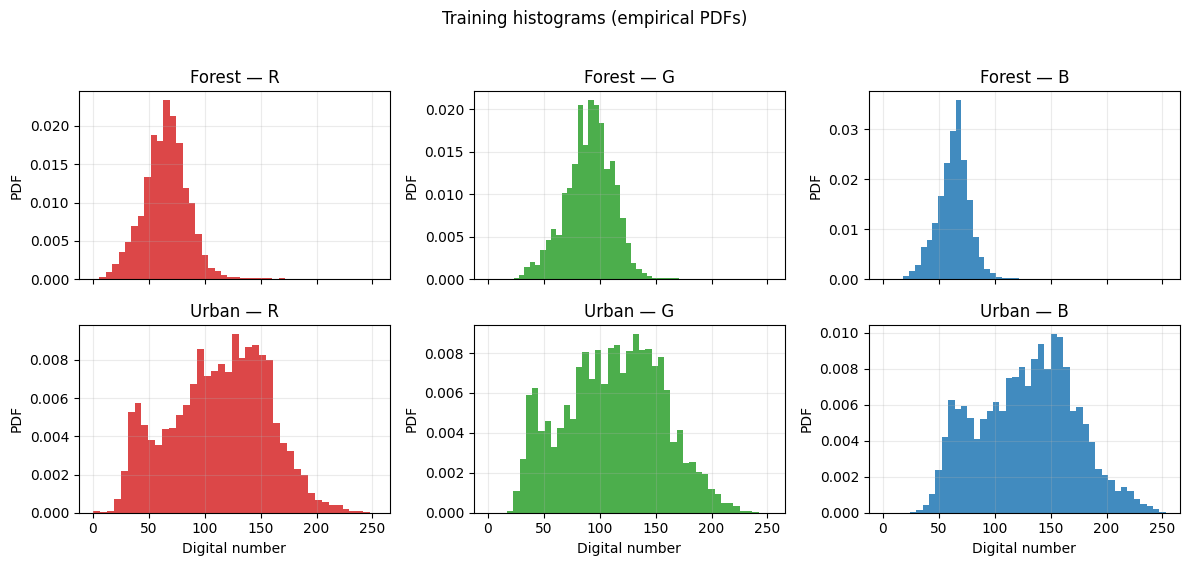

In [4]:
# Per-channel histograms of the pure training classes
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True)
channel_names = ('R', 'G', 'B')
colors = ('tab:red', 'tab:green', 'tab:blue')

for c in range(3):
    axes[0, c].hist(X_forest[:, c], bins=40, density=True, color=colors[c], alpha=0.85)
    axes[0, c].set_title(f'Forest — {channel_names[c]}')
    axes[0, c].set_ylabel('PDF')
    axes[0, c].grid(True, alpha=0.25)

    axes[1, c].hist(X_urban[:, c], bins=40, density=True, color=colors[c], alpha=0.85)
    axes[1, c].set_title(f'Urban — {channel_names[c]}')
    axes[1, c].set_xlabel('Digital number')
    axes[1, c].set_ylabel('PDF')
    axes[1, c].grid(True, alpha=0.25)

plt.suptitle('Training histograms (empirical PDFs)', y=1.02)
plt.tight_layout()
plt.show()

## 1. Bayes classifier from scratch

### Model

For each class $\omega \in \{\text{forest},\text{urban}\}$ we fit a **multivariate Gaussian** on the RGB vector $\mathbf{x} \in \mathbb{R}^3$:

$$
p(\mathbf{x}\mid\omega)
= \frac{1}{(2\pi)^{d/2}|\Sigma_\omega|^{1/2}}
\exp\!\left(-\tfrac{1}{2}(\mathbf{x}-\boldsymbol{\mu}_\omega)^\top
\Sigma_\omega^{-1}(\mathbf{x}-\boldsymbol{\mu}_\omega)\right)
$$

Equal priors $P(\omega)=1/2$ (same number of training pixels). Decision:

$$
\hat{\omega}(\mathbf{x})
= \arg\max_\omega \big[\log p(\mathbf{x}\mid\omega) + \log P(\omega)\big]
$$

As extra analysis we also fit **independent univariate Gaussians per channel** and compare both maps.

In [5]:
def fit_gaussian(X):
    """Estimate mean and covariance of a multivariate Gaussian."""
    mu = X.mean(axis=0)
    cov = np.cov(X, rowvar=False) + 1e-6 * np.eye(X.shape[1])
    return mu, cov


def log_gaussian(X, mu, cov):
    """Log-density of N(mu, cov) for each row of X."""
    d = X.shape[1]
    diff = X - mu
    inv = np.linalg.inv(cov)
    _, logdet = np.linalg.slogdet(cov)
    quad = np.sum(diff @ inv * diff, axis=1)
    return -0.5 * (d * np.log(2 * np.pi) + logdet + quad)


mu_f, cov_f = fit_gaussian(X_forest)
mu_u, cov_u = fit_gaussian(X_urban)

print('Forest mean μ_f =', np.round(mu_f, 2))
print('Urban  mean μ_u =', np.round(mu_u, 2))
print('\nForest covariance Σ_f =\n', np.round(cov_f, 2))
print('\nUrban  covariance Σ_u =\n', np.round(cov_u, 2))

Forest mean μ_f = [65.26 90.8  63.39]
Urban  mean μ_u = [112.12 111.91 128.74]

Forest covariance Σ_f =
 [[417.01 414.97 241.13]
 [414.97 447.39 247.32]
 [241.13 247.32 223.82]]

Urban  covariance Σ_u =
 [[1920.44 1749.58 1648.23]
 [1749.58 1909.14 1817.7 ]
 [1648.23 1817.7  1852.75]]


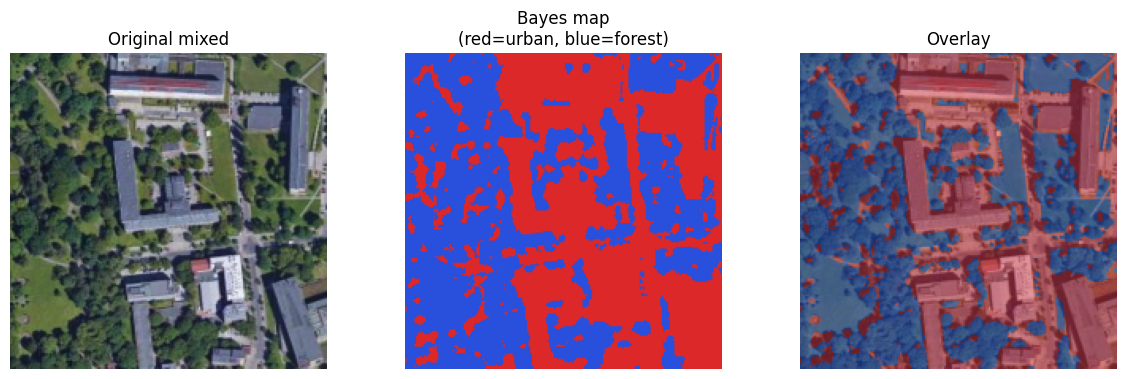

Bayes class share — urban: 50.2% | forest: 49.8%


In [6]:
# Bayes decision with equal priors
prior = 0.5
log_post_f = log_gaussian(X_test, mu_f, cov_f) + np.log(prior)
log_post_u = log_gaussian(X_test, mu_u, cov_u) + np.log(prior)

labels_bayes = (log_post_u > log_post_f).astype(np.uint8).reshape(mixed_img.shape[:2])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(mixed_img)
axes[0].set_title('Original mixed')
axes[1].imshow(colourise(labels_bayes, mixed_img.shape))
axes[1].set_title('Bayes map\n(red=urban, blue=forest)')
axes[2].imshow(overlay(mixed_img, labels_bayes))
axes[2].set_title('Overlay')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

u_pct, f_pct = class_share(labels_bayes)
print(f'Bayes class share — urban: {u_pct:.1f}% | forest: {f_pct:.1f}%')

Univariate forest μ, σ²: [65.26 90.8  63.39] | [417.   447.38 223.82]
Univariate urban  μ, σ²: [112.12 111.91 128.74] | [1920.39 1909.09 1852.71]
Agreement with multivariate Bayes: 79.5%


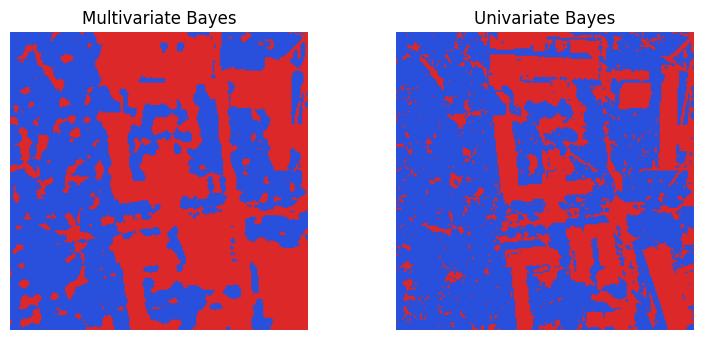

In [7]:
# Extra: independent univariate Gaussians per channel (diagonal covariance)
def fit_univariate(X):
    mu = X.mean(axis=0)
    var = X.var(axis=0) + 1e-6
    return mu, var


def log_univariate(X, mu, var):
    return np.sum(-0.5 * (np.log(2 * np.pi * var) + (X - mu) ** 2 / var), axis=1)


mu_f1, var_f1 = fit_univariate(X_forest)
mu_u1, var_u1 = fit_univariate(X_urban)

log_f1 = log_univariate(X_test, mu_f1, var_f1) + np.log(0.5)
log_u1 = log_univariate(X_test, mu_u1, var_u1) + np.log(0.5)
labels_uni = (log_u1 > log_f1).astype(np.uint8).reshape(mixed_img.shape[:2])

agree = 100.0 * np.mean(labels_uni == labels_bayes)
print('Univariate forest μ, σ²:', np.round(mu_f1, 2), '|', np.round(var_f1, 2))
print('Univariate urban  μ, σ²:', np.round(mu_u1, 2), '|', np.round(var_u1, 2))
print(f'Agreement with multivariate Bayes: {agree:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(colourise(labels_bayes, mixed_img.shape))
axes[0].set_title('Multivariate Bayes')
axes[1].imshow(colourise(labels_uni, mixed_img.shape))
axes[1].set_title('Univariate Bayes')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Bayes — notes

- Forest pixels are darker / greener (lower mean, smaller variance); urban pixels are brighter and more spread out — visible in the histograms and in $\boldsymbol{\mu},\Sigma$.
- The multivariate model uses full RGB covariance (channel correlations). The univariate model ignores correlations; agreement between the two is reported above.
- Equal priors fit this setup because both training patches have the same size.

## 2. k-NN classifier from scratch

For a test pixel $\mathbf{x}$, find the $k$ nearest training pixels in RGB Euclidean space and take a majority vote.

Full training would be $2 \times 200 \times 200 = 80\,000$ pixels. We **subsample** $n$ pixels per class, then classify all test pixels with vectorised `cdist` (no scikit-learn).

In [8]:
def knn_predict(X_train, y_train, X_query, k):
    """Majority-vote k-NN. Labels: 1 = urban, 0 = forest."""
    D = cdist(X_query, X_train, metric='euclidean')
    nn = np.argpartition(D, kth=k - 1, axis=1)[:, :k]
    votes = y_train[nn]
    # majority; on a tie (even k) prefer urban when sum*2 >= k
    return (votes.sum(axis=1) * 2 >= k).astype(np.uint8)


n_per_class = 1500
idx_f = np.random.choice(len(X_forest), n_per_class, replace=False)
idx_u = np.random.choice(len(X_urban), n_per_class, replace=False)

X_train = np.vstack([X_forest[idx_f], X_urban[idx_u]])
y_train = np.hstack([
    np.zeros(n_per_class, dtype=np.uint8),
    np.ones(n_per_class, dtype=np.uint8),
])

print('k-NN training set:', X_train.shape, '| test pixels:', X_test.shape[0])

k-NN training set: (3000, 3) | test pixels: 40000


k=1: urban 53.7% | forest 46.3%


k=3: urban 51.1% | forest 48.9%


k=5: urban 49.2% | forest 50.8%


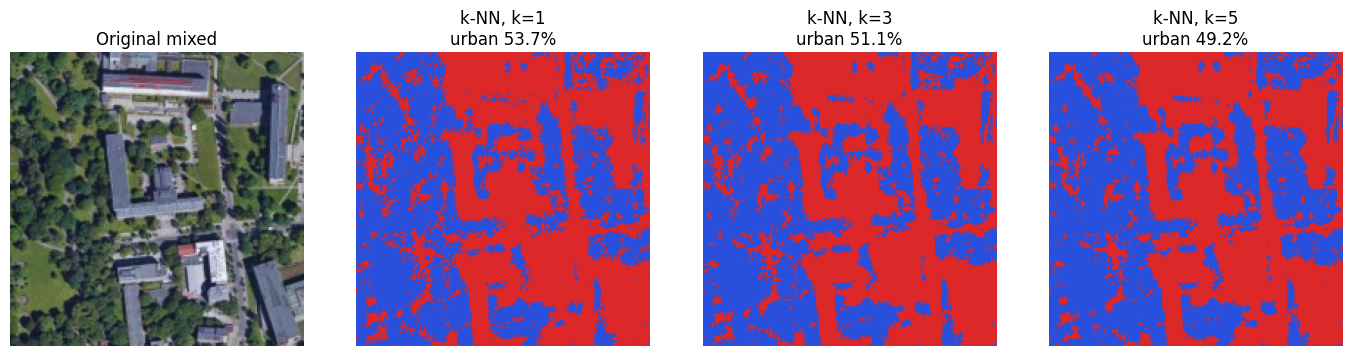

In [9]:
ks = [1, 3, 5]
knn_maps = {}

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(mixed_img)
axes[0].set_title('Original mixed')
axes[0].axis('off')

for i, k in enumerate(ks):
    labels = knn_predict(X_train, y_train, X_test, k).reshape(mixed_img.shape[:2])
    knn_maps[k] = labels
    u_pct, f_pct = class_share(labels)
    axes[i + 1].imshow(colourise(labels, mixed_img.shape))
    axes[i + 1].set_title(f'k-NN, k={k}\nurban {u_pct:.1f}%')
    axes[i + 1].axis('off')
    print(f'k={k}: urban {u_pct:.1f}% | forest {f_pct:.1f}%')

plt.tight_layout()
plt.show()

### Effect of $k$

- **$k=1$**: follows the single nearest neighbour. Boundaries are sharp, but isolated mislabels appear as salt-and-pepper noise.
- **$k=3$**: majority over three neighbours already smooths most speckles; class regions look more coherent.
- **$k=5$**: still smoother / slightly more stable shares; extra cost is small here because distance computation dominates, not the vote.

Larger $k$ reduces variance of the decision but can blur thin structures. For this RGB land-cover task, $k=3$ or $k=5$ is a good compromise.

## 3. Extra analysis — Bayes vs k-NN

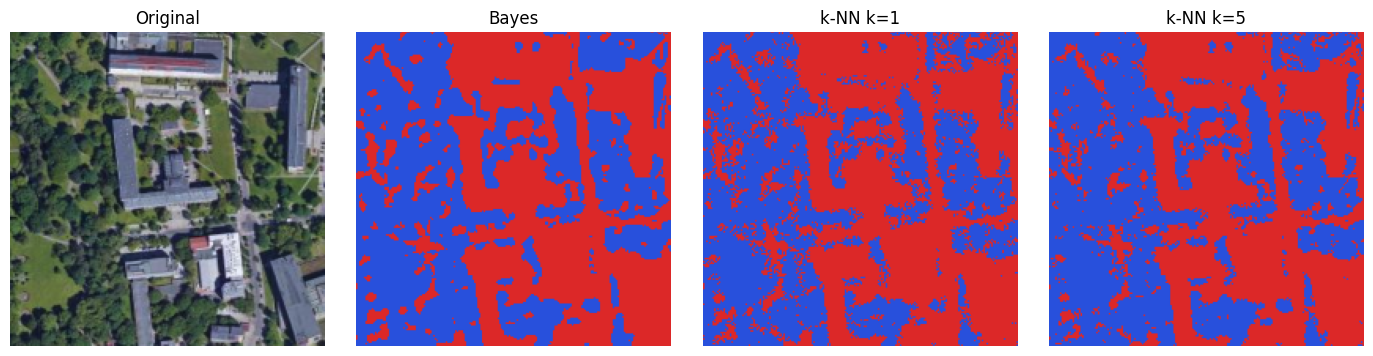

Bayes       urban= 50.2%  forest= 49.8%  agree with Bayes=100.0%
k-NN k=1    urban= 53.7%  forest= 46.3%  agree with Bayes= 89.9%
k-NN k=3    urban= 51.1%  forest= 48.9%  agree with Bayes= 92.1%
k-NN k=5    urban= 49.2%  forest= 50.8%  agree with Bayes= 92.9%


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(mixed_img); axes[0].set_title('Original')
axes[1].imshow(colourise(labels_bayes, mixed_img.shape)); axes[1].set_title('Bayes')
axes[2].imshow(colourise(knn_maps[1], mixed_img.shape)); axes[2].set_title('k-NN k=1')
axes[3].imshow(colourise(knn_maps[5], mixed_img.shape)); axes[3].set_title('k-NN k=5')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

for name, lab in [('Bayes', labels_bayes),
                  ('k-NN k=1', knn_maps[1]),
                  ('k-NN k=3', knn_maps[3]),
                  ('k-NN k=5', knn_maps[5])]:
    u_pct, f_pct = class_share(lab)
    agree = 100.0 * np.mean(lab == labels_bayes)
    print(f'{name:10s}  urban={u_pct:5.1f}%  forest={f_pct:5.1f}%  agree with Bayes={agree:5.1f}%')

## Summary

1. **Bayes**: parametric Gaussian PDFs estimated from pure forest/urban patches; each mixed pixel is assigned to the class with higher posterior. Multivariate RGB modelling is the main result; univariate Gaussians are a simpler baseline.
2. **k-NN**: non-parametric alternative using Euclidean distance in RGB. $k=1$ is noisy; $k=3$ and $k=5$ give smoother maps.
3. **Comparison**: both methods recover the same broad land-cover pattern. Bayes is fast and smooth under the Gaussian assumption; k-NN adapts locally but needs subsampling for speed and is sensitive to $k$.

AI tools were applied for formatting and plotting results.